Import everything

In [4]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.mplot3d import Axes3D

import numpy as np
from nexusformat.nexus import nxload
from pathlib import Path
from scipy.integrate import simpson 
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import datetime
import csv
import pptx
import pptx.util
import os

Create class to read in and give data

In [5]:
class Nexus_handling:
    def get_nexus_data_I06(self,file):
        """Function that loads the data from a nexus file and returns it as a list of numpy
arrays"""
        entry_string = "entry"
        data_region_list = []
        metadata_region_list = None
        x_array = file[entry_string]["instrument"]["fastEnergy"]["value"].nxvalue
        y_array = file[entry_string]["instrument"]["fesData"]["C1"].nxvalue
        data_region_list.append({"x": x_array, "y": y_array})
        y_array = file[entry_string]["instrument"]["fesData"]["C5"].nxvalue
        data_region_list.append({"x": x_array, "y": y_array})
        y_array = file[entry_string]["instrument"]["fesData"]["idio"].nxvalue
        data_region_list.append({"x": x_array, "y": y_array})
        y_array = file[entry_string]["instrument"]["fesData"]["ifiofb"].nxvalue
        data_region_list.append({"x": x_array, "y": y_array})
        magnet_field = file[entry_string]["instrument"]["scm"]["field_z"].nxvalue
        metadata_region_list = {"magnet_ﬁeld": magnet_field}
        polar = file[entry_string]["instrument"]["id"]["polarisation"].nxvalue
        metadata_region_list["polarisation"] = polar
        temp = file[entry_string]["instrument"]["scm"]["T_sample"].nxvalue
        metadata_region_list["T_sample"] = temp
        ###Add temperature values here
        ### Add angle of the beam here => 
        return data_region_list, metadata_region_list

    def open_single_spectra(self,ﬁle_number,directory_path,ﬁle_preﬁx,sensor):
        ﬁle_name = directory_path + ﬁle_preﬁx + str(ﬁle_number) + ".nxs"
        spectra_ﬁle = nxload(ﬁle_name)
        data,meta_data = self.get_nexus_data_I06(spectra_ﬁle)
        if sensor == "TEY":
            spectra = {"x" : data[2]["x"],"y":data[2]["y"],"meta" : meta_data}
        elif sensor == "TFY":
            spectra = {"x" : data[3]["x"],"y":data[3]["y"],"meta" : meta_data}
        return spectra

class XMCD_data_analysis(Nexus_handling):
    def __init__(self):
        self.on_oI_edge_points = [571, 576.9]
        self.directory_path = None
        self.ﬁle_preﬁx = None
        self.energy = None
        self.spectra = []
        self.hyst = []
        self.XMCD = []
        self.magz = []
        #self.temperature
   

    def set_directory_path(self, directory_path):
        self.directory_path = directory_path

    def set_ﬁle_preﬁx(self, ﬁle_preﬁx):
        self.ﬁle_preﬁx = ﬁle_preﬁx

    def load_spectra(self, directory_path, ﬁle_preﬁx, XMCD_spectra_Set,sensor = "TEY"):  
        self.directory_path = directory_path
        self.ﬁle_preﬁx = ﬁle_preﬁx

        if len(XMCD_spectra_Set) != 1:
            for ﬁle_number in XMCD_spectra_Set: 
                # print(file_number)
                data_set = self.open_single_spectra(ﬁle_number, directory_path,  ﬁle_preﬁx,sensor)
                self.spectra.append(data_set)
                self.energy = self.spectra[0]["x"]
        else:
            # print(XMCD_spectra_Set)
            data_set = self.open_single_spectra(XMCD_spectra_Set[0], directory_path,  ﬁle_preﬁx,sensor)
            self.spectra.append(data_set)
    
            self.energy = self.spectra[0]["x"]

In [17]:
class Load_file():

    def __init__(self, path):
        self.path = path

        nexus = nxload(self.path)
        self._get_attributes_(nexus)

    def _get_attributes_(self, nexus):
        ("Get attributes from nexus file")
        self.TEY = nexus["entry"]["instrument"]["fesData"]["C1"].nxvalue
        self.TFY = nexus["entry"]["instrument"]["fesData"]["C5"].nxvalue
        self.Field = nexus["entry"]["instrument"]["scm"]["field_z"].nxvalue
        self.T_sample = nexus["entry"]["instrument"]["scm"]["T_sample"].nxvalue
        self.polarisation = nexus["entry"]["instrument"]["id"]["polarisation"].nxvalue
        self.energy = nexus["entry"]["instrument"]["fastEnergy"]["value"].nxvalue
        self.I0 = nexus["entry"]["instrument"]["fesData"]["C2"].nxvalue


class XMCD():
    def __init__(self, path_pc, path_nc, create_fig=False):

        self.XMCD_edge1 = 576.8
        self.XMCD_edge2 = 578

        self.path_pc = path_pc
        self.path_nc = path_nc

        self.file_pc = Load_file(self.path_pc) 
        self.file_nc = Load_file(self.path_nc) 

        if self.file_pc.polarisation != "pc" or self.file_nc.polarisation != "nc":
            raise ValueError(f"Polarisation of the files does not match the expected values (pc {self.file_pc.polarisation} and nc {self.file_nc.polarisation})")

        self.energy = self.file_pc.energy
        if create_fig:
            fig, [self.rawXASax, self.XMCDax] = plt.subplots(1,2, sharey=True)

    def plot_raw(self):
        self.rawXASax.plot(self.file_pc.energy, self.file_pc.TEY, label="TEY PC")
        self.rawXASax.plot(self.file_nc.energy, self.file_nc.TEY, label="TEY NC")
        self.rawXASax.set_ylabel("Intensity")
        self.rawXASax.legend()
        self.XMCDax.plot(self.energy, (self.file_pc.TEY - self.file_nc.TEY), label="XMCD")
        self.XMCDax.axvline(x=self.XMCD_edge1, color='r', linestyle='--', label="576.8")
        self.XMCDax.axvline(x=self.XMCD_edge2, color='g', linestyle='--', label="578")
        self.XMCDax.set_xlabel("Energy (eV)")
        self.XMCDax.legend()

        plt.tight_layout()
        plt.draw()

    def calculate_XMCD_integrate(self, plot=False):
        if plot:
            self.plot_normalised()
        else:
            self.normalise_XAS()

        """Calculate the XMCD by integrating the spectra between the given energy range"""
        self.XMCD_spectra = self.file_pc.TEY - self.file_nc.TEY
        edge1_mask = (self.energy >= self.XMCD_edge1-0.5) & (self.energy <= self.XMCD_edge1+0.5)
        edge2_mask = (self.energy >= self.XMCD_edge2-0.5) & (self.energy <= self.XMCD_edge2+0.5)

        Xmcd1 = np.trapezoid(self.XMCD_spectra[edge1_mask], self.energy[edge1_mask])
        Xmcd2 = np.trapezoid(self.XMCD_spectra[edge2_mask], self.energy[edge2_mask])
        if plot:
            self.XMCDax.plot(self.energy[edge1_mask], self.XMCD_spectra[edge1_mask], label="Edge 1 Region", color='orange')
            self.XMCDax.plot(self.energy[edge2_mask], self.XMCD_spectra[edge2_mask], label="Edge 2 Region", color='purple')
            self.XMCDax.legend()

        XMCD = Xmcd1 - Xmcd2
        return XMCD
    
    def normalise_XAS(self):
        """Normalise the XAS spectra by dividing by the maximum value"""
        self.file_pc.TEY /= self.file_pc.I0
        self.file_nc.TEY /= self.file_nc.I0

        self.file_pc.TEY -= np.mean(self.file_pc.TEY[:50])
        self.file_nc.TEY -= np.mean(self.file_nc.TEY[:50])

    def plot_normalised(self):
        self.normalise_XAS()
        self.rawXASax.clear()
        self.XMCDax.clear()

        self.rawXASax.plot(self.file_pc.energy, self.file_pc.TEY, label="TEY PC")
        self.rawXASax.plot(self.file_nc.energy, self.file_nc.TEY, label="TEY NC")
        self.rawXASax.set_ylabel("Normalised Intensity")
        self.rawXASax.legend()
        self.XMCDax.plot(self.energy, (self.file_pc.TEY - self.file_nc.TEY), label="XMCD")
        self.XMCDax.axvline(x=self.XMCD_edge1, color='r', linestyle='--', label="576.8")
        self.XMCDax.axvline(x=self.XMCD_edge2, color='g', linestyle='--', label="578")
        self.XMCDax.set_xlabel("Energy (eV)")
        self.XMCDax.legend()

        plt.tight_layout()
        plt.draw()


In [29]:
def hysteresis_loop(list):

    pc_list = []
    nc_list = []

    for file in list:
        if Load_file(file).polarisation == "pc":
            pc_list.append(Load_file(file))
        elif Load_file(file).polarisation == "nc":
            nc_list.append(Load_file(file))
        else:
            raise ValueError(f"Polarisation of the file {file} does not match the expected values (pc or nc)")
    
    new_fig = plt.figure(figsize=(10,6))

    for i, pc_file in enumerate(pc_list):
        matching_nc_file = nc_list[i] if i < len(nc_list) else None 
        if matching_nc_file is not None:
            # print(f"Matching files found: {pc_file.path} and {matching_nc_file.path}")
            xmcd = XMCD(pc_file.path, matching_nc_file.path, create_fig=True)
            xmcd.plot_raw()
            xmcd.calculate_XMCD_integrate()

            field = (pc_file.Field + matching_nc_file.Field)/2

            new_fig.scatter(field, xmcd.calculate_XMCD_integrate(), label=f"T={pc_file.T_sample}K")

    new_fig.show()

    

            
            
    




AttributeError: 'Figure' object has no attribute 'scatter'

<Figure size 1000x600 with 0 Axes>

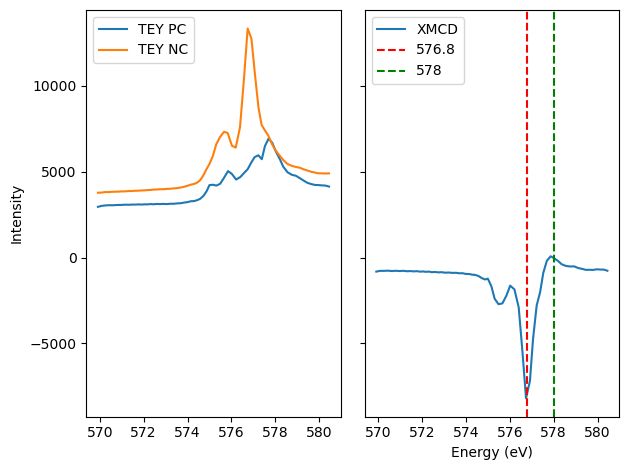

In [28]:
data_dir = Path(r"C:\Users\ppxfc1\OneDrive - The University of Nottingham\Desktop\PhD\Code\PhD-Codes\Analysis code\CrCl3_XMCD_feb26\Hyst_2k_GI")

files = [( data_dir / f.name) for f in data_dir.iterdir() if f.is_file()]
files.sort()

hysteresis_loop(files)
    

